## Introduction to Machine Learning

## Decision Trees, Bagging and Boosting

**Soumik Bhattacharyya**  
**MDE2026005**

The notebook uses the Breast Cancer Wisconsin (Diagnostic) dataset. The positive-class convention is **class 1 (benign)**, matching scikit-learn's default positive label for this dataset. The held-out test set is reserved for final evaluation; validation data is drawn only from the training partition.

## Task 1 — Data Exploration and Preparation

### Question 1

In [1]:
import time
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

RANDOM_STATE = 42
POSITIVE_LABEL = 1

# Load the Breast Cancer Wisconsin dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

# First five observations, dimensions, feature/target names, and data types
display(X.head())
print("Dataset dimensions:", X.shape)
print("Target dimensions:", y.shape)
print("Feature names:", list(X.columns))
print("Target names:", list(data.target_names))
print("\\nFeature data types:")
print(X.dtypes)
print("\\nTarget data type:", y.dtype)

# Missing values, duplicate rows, class counts, and class proportions
print("\\nMissing values:", int(X.isna().sum().sum()))
print("Duplicate feature rows:", int(X.duplicated().sum()))
print("\\nClass counts:")
display(y.value_counts().sort_index().rename(index=dict(enumerate(data.target_names))))
print("\\nClass proportions:")
display(y.value_counts(normalize=True).sort_index().rename(index=dict(enumerate(data.target_names))))

# Required stratified 80:20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\\nTraining samples:", len(X_train))
print("Test samples:", len(X_test))
print("Training class counts:")
display(y_train.value_counts().sort_index())
print("Test class counts:")
display(y_test.value_counts().sort_index())

assert set(y_train.unique()) == set(y.unique())
assert set(y_test.unique()) == set(y.unique())


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Dataset dimensions: (569, 30)
Target dimensions: (569,)
Feature names: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
Target names: [np.str_('malignant'), np.str_('benign')]
\nFeature data types:
mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        flo

target
malignant    212
benign       357
Name: count, dtype: int64

\nClass proportions:


target
malignant    0.372583
benign       0.627417
Name: proportion, dtype: float64

\nTraining samples: 455
Test samples: 114
Training class counts:


target
0    170
1    285
Name: count, dtype: int64

Test class counts:


target
0    42
1    72
Name: count, dtype: int64

Using identical training and test partitions makes model comparisons more meaningful because every model is evaluated on the same observations. Differences in metrics are therefore less likely to be caused by different data splits. Tree-based models generally do not require feature scaling, so the original numerical features are retained without scaling.

## Task 2 — Decision Tree Classifier

### Question 5

In [2]:
def evaluate_classifier(model, X_fit, y_fit, X_eval, y_eval):
    model.fit(X_fit, y_fit)
    predictions_train = model.predict(X_fit)
    predictions_test = model.predict(X_eval)

    result = {
        "Training accuracy": accuracy_score(y_fit, predictions_train),
        "Test accuracy": accuracy_score(y_eval, predictions_test),
        "Test precision": precision_score(
            y_eval, predictions_test, pos_label=POSITIVE_LABEL, zero_division=0
        ),
        "Test recall": recall_score(
            y_eval, predictions_test, pos_label=POSITIVE_LABEL, zero_division=0
        ),
        "Test F1-score": f1_score(
            y_eval, predictions_test, pos_label=POSITIVE_LABEL, zero_division=0
        ),
        "Confusion matrix": confusion_matrix(
            y_eval, predictions_test, labels=[0, 1]
        )
    }
    return result


# Baseline DecisionTreeClassifier; unspecified parameters retain sklearn defaults.
baseline_tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
baseline_tree_result = evaluate_classifier(
    baseline_tree, X_train, y_train, X_test, y_test
)
print("Baseline tree settings:", baseline_tree.get_params())
print({k: v for k, v in baseline_tree_result.items() if k != "Confusion matrix"})
print("Confusion matrix (rows=true [0,1], columns=predicted [0,1]):")
print(baseline_tree_result["Confusion matrix"])


Baseline tree settings: {'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}
{'Training accuracy': 1.0, 'Test accuracy': 0.9122807017543859, 'Test precision': 0.9558823529411765, 'Test recall': 0.9027777777777778, 'Test F1-score': 0.9285714285714286}
Confusion matrix (rows=true [0,1], columns=predicted [0,1]):
[[39  3]
 [ 7 65]]


### Question 6

In [3]:
DEPTH_VALUES = [2, 3, 5, None]
depth_models = {}
depth_results = []

for depth in DEPTH_VALUES:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=RANDOM_STATE
    )
    result = evaluate_classifier(model, X_train, y_train, X_test, y_test)
    depth_models[depth] = model
    depth_results.append({
        "max_depth": "None" if depth is None else depth,
        **{key: value for key, value in result.items()
           if key != "Confusion matrix"}
    })

depth_results_df = pd.DataFrame(depth_results)
display(depth_results_df)


,max_depth,Training accuracy,Test accuracy,Test precision,Test recall,Test F1-score
0,2,0.958242,0.894737,0.968750,0.861111,0.911765
1,3,0.975824,0.938596,0.945205,0.958333,0.951724
2,5,0.993407,0.921053,0.956522,0.916667,0.936170
3,None,1.000000,0.912281,0.955882,0.902778,0.928571


### Question 7

In [4]:
depth_confusion_matrices = {}
for depth, model in depth_models.items():
    predictions = model.predict(X_test)
    depth_confusion_matrices[depth] = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    )
    print(f"max_depth={depth}")
    print(depth_confusion_matrices[depth])


max_depth=2
[[40  2]
 [10 62]]
max_depth=3
[[38  4]
 [ 3 69]]
max_depth=5
[[39  3]
 [ 6 66]]
max_depth=None
[[39  3]
 [ 7 65]]


### Question 8

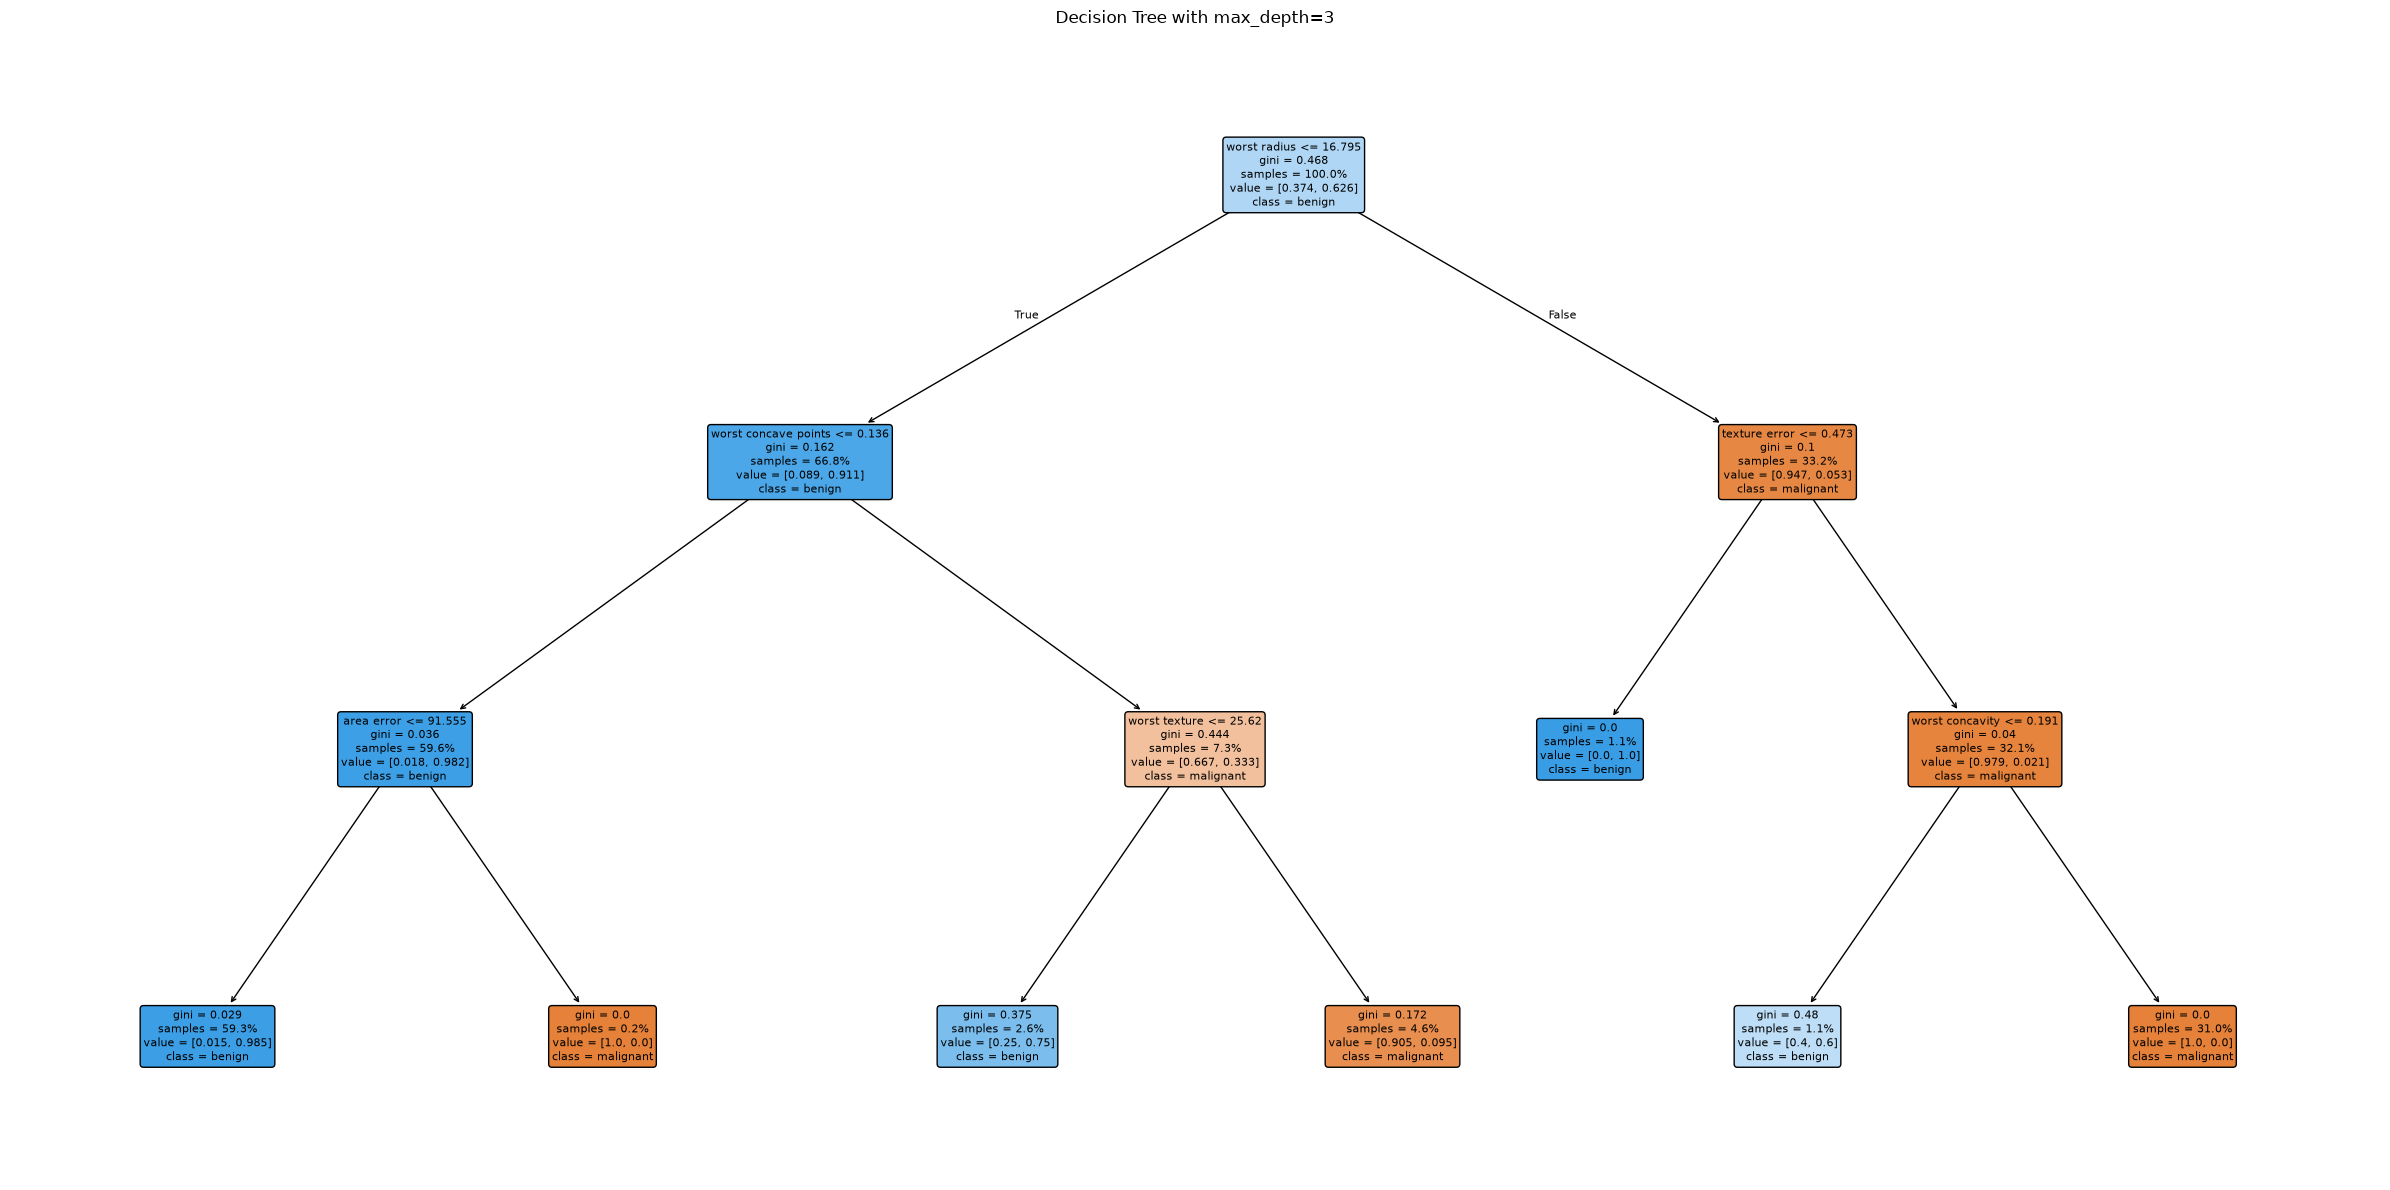

In [5]:
tree_depth_3 = depth_models[3]

plt.figure(figsize=(24, 12))
plot_tree(
    tree_depth_3,
    feature_names=list(X.columns),
    class_names=list(data.target_names),
    filled=True,
    rounded=True,
    proportion=True,
    fontsize=8
)
plt.title("Decision Tree with max_depth=3")
plt.tight_layout()
plt.show()


** Two decision paths/rules:**

Two decision paths from the depth-3 tree are:

1. If worst radius <= 16.795, worst concave points <= 0.136, and area error <= 91.555, the observation is classified as benign.

2. If worst radius > 16.795, texture error > 0.473, and worst concavity > 0.191, the observation is classified as malignant.

The tree uses these feature thresholds to progressively separate observations into increasingly homogeneous groups. The resulting paths provide interpretable classification rules.


### Question 9

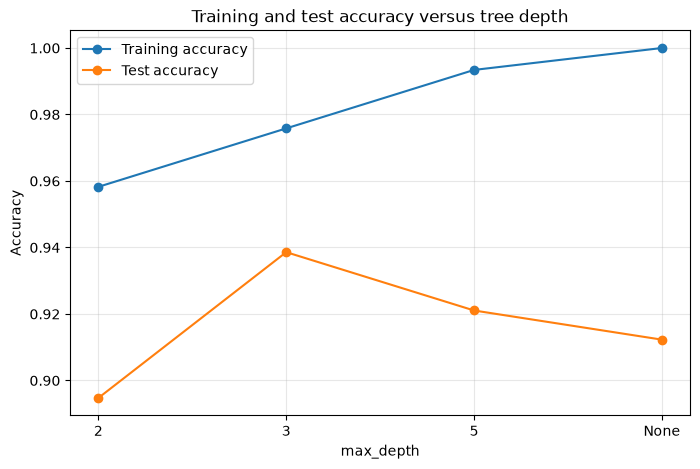

In [6]:
depth_plot_df = depth_results_df.copy()
depth_plot_df["max_depth_numeric"] = [
    np.inf if value == "None" else float(value)
    for value in depth_plot_df["max_depth"]
]
depth_plot_df = depth_plot_df.sort_values("max_depth_numeric")

plt.figure(figsize=(8, 5))
plt.plot(
    depth_plot_df["max_depth"].astype(str),
    depth_plot_df["Training accuracy"],
    marker="o",
    label="Training accuracy"
)
plt.plot(
    depth_plot_df["max_depth"].astype(str),
    depth_plot_df["Test accuracy"],
    marker="o",
    label="Test accuracy"
)
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Training and test accuracy versus tree depth")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Interpretation of underfitting, overfitting, or trade-off:**

Training accuracy increases consistently with tree depth, from 0.958 at depth 2 to 1.000 for an unrestricted tree. Test accuracy initially increases from 0.895 at depth 2 to 0.939 at depth 3, but decreases to 0.921 at depth 5 and 0.912 for the unrestricted tree.

The depth-2 tree shows signs of underfitting, while the unrestricted tree shows a larger training-test performance gap, suggesting overfitting. Depth 3 provides the best trade-off among the tested configurations, achieving the highest test accuracy and F1-score of 0.952.


## Task 3 — Impurity Measures and Split Reasoning

### Question 10

Gini impurity measures the probability of incorrectly classifying a randomly selected observation if its class label were assigned according to the class distribution in a node. It is calculated as \(Gini = 1 - \\sum_i p_i^2\), where \(p_i\) is the proportion of class \(i\). Entropy measures class uncertainty and is calculated as \(H = -\\sum_i p_i \\log_2(p_i)\). An impurity value of zero means that all observations in the node belong to a single class, so the node is pure.

### Question 11

In [7]:
criterion_models = {}
criterion_rows = []

for criterion in ["gini", "entropy"]:
    model = DecisionTreeClassifier(
        criterion=criterion,
        random_state=RANDOM_STATE
    )
    result = evaluate_classifier(model, X_train, y_train, X_test, y_test)
    criterion_models[criterion] = model
    criterion_rows.append({
        "Criterion": criterion,
        **{key: value for key, value in result.items()
           if key != "Confusion matrix"}
    })
    print(f"Criterion: {criterion}")
    print("Tree depth:", model.get_depth())
    print("Number of leaves:", model.get_n_leaves())
    print("Confusion matrix:")
    print(result["Confusion matrix"])

criterion_results_df = pd.DataFrame(criterion_rows)
display(criterion_results_df)

gini_predictions = criterion_models["gini"].predict(X_test)
entropy_predictions = criterion_models["entropy"].predict(X_test)
print("Number of different test predictions:",
      int(np.sum(gini_predictions != entropy_predictions)))


Criterion: gini
Tree depth: 7
Number of leaves: 19
Confusion matrix:
[[39  3]
 [ 7 65]]
Criterion: entropy
Tree depth: 6
Number of leaves: 16
Confusion matrix:
[[40  2]
 [ 8 64]]


,Criterion,Training accuracy,Test accuracy,Test precision,Test recall,Test F1-score
0,gini,1.0,0.912281,0.955882,0.902778,0.928571
1,entropy,1.0,0.912281,0.969697,0.888889,0.927536


Number of different test predictions: 6


**Comparison of the observed metrics, learned trees, and predictions:**

Both Gini and entropy trees achieve 1.000 training accuracy and 0.912 test accuracy. The Gini tree achieves precision of 0.956, recall of 0.903, and F1-score of 0.929, while the entropy tree achieves precision of 0.970, recall of 0.889, and F1-score of 0.928.

The Gini tree has depth 7 and 19 leaves, whereas the entropy tree has depth 6 and 16 leaves. Their predictions differ for six test observations. Although their overall performance is nearly identical, entropy produces slightly higher precision, while Gini produces slightly higher recall and F1-score.

### Question 12

In [8]:
# Numerical example of a candidate split.
# Parent: 10 observations (6 class-0, 4 class-1).
# Left child: 5 observations (4 class-0, 1 class-1).
# Right child: 5 observations (2 class-0, 3 class-1).

def gini_from_counts(counts):
    counts = np.asarray(counts, dtype=float)
    probabilities = counts / counts.sum()
    return 1.0 - np.sum(probabilities ** 2)

parent_counts = [6, 4]
left_counts = [4, 1]
right_counts = [2, 3]

parent_impurity = gini_from_counts(parent_counts)
left_impurity = gini_from_counts(left_counts)
right_impurity = gini_from_counts(right_counts)

n_parent = sum(parent_counts)
n_left = sum(left_counts)
n_right = sum(right_counts)

weighted_child_impurity = (
    (n_left / n_parent) * left_impurity
    + (n_right / n_parent) * right_impurity
)
impurity_reduction = parent_impurity - weighted_child_impurity

print("Parent Gini impurity:", parent_impurity)
print("Left child Gini impurity:", left_impurity)
print("Right child Gini impurity:", right_impurity)
print("Weighted child impurity:", weighted_child_impurity)
print("Impurity reduction:", impurity_reduction)


Parent Gini impurity: 0.48
Left child Gini impurity: 0.31999999999999984
Right child Gini impurity: 0.48
Weighted child impurity: 0.3999999999999999
Impurity reduction: 0.08000000000000007


### Question 13

A decision tree can change when the training data changes because different observations can alter class proportions and the candidate split that gives the greatest impurity reduction. Randomness in the estimator, including feature ordering or random feature selection when applicable, can also affect the learned structure; setting a fixed random seed improves reproducibility. An advantage of a single decision tree is interpretability: its decisions can be represented as human-readable rules. A limitation is its high variance, since small changes in training data can produce a substantially different tree.

## Task 4 — Bootstrap Aggregation (Bagging)

### Question 14

In [9]:
# Handle the estimator/base_estimator parameter difference across sklearn versions.
bagging_signature = inspect.signature(BaggingClassifier)
bagging_kwargs = {
    "n_estimators": 100,
    "random_state": RANDOM_STATE
}
if "estimator" in bagging_signature.parameters:
    bagging_kwargs["estimator"] = DecisionTreeClassifier(random_state=RANDOM_STATE)
else:
    bagging_kwargs["base_estimator"] = DecisionTreeClassifier(random_state=RANDOM_STATE)

bagging_model = BaggingClassifier(**bagging_kwargs)
bagging_result = evaluate_classifier(
    bagging_model, X_train, y_train, X_test, y_test
)

print("Bagging settings:", bagging_model.get_params())
print({k: v for k, v in bagging_result.items() if k != "Confusion matrix"})
print("Confusion matrix:")
print(bagging_result["Confusion matrix"])


Bagging settings: {'bootstrap': True, 'bootstrap_features': False, 'estimator__ccp_alpha': 0.0, 'estimator__class_weight': None, 'estimator__criterion': 'gini', 'estimator__max_depth': None, 'estimator__max_features': None, 'estimator__max_leaf_nodes': None, 'estimator__min_impurity_decrease': 0.0, 'estimator__min_samples_leaf': 1, 'estimator__min_samples_split': 2, 'estimator__min_weight_fraction_leaf': 0.0, 'estimator__monotonic_cst': None, 'estimator__random_state': 42, 'estimator__splitter': 'best', 'estimator': DecisionTreeClassifier(random_state=42), 'max_features': 1.0, 'max_samples': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}
{'Training accuracy': 1.0, 'Test accuracy': 0.9385964912280702, 'Test precision': 0.9452054794520548, 'Test recall': 0.9583333333333334, 'Test F1-score': 0.9517241379310345}
Confusion matrix:
[[38  4]
 [ 3 69]]


### Question 15

In [10]:
bagging_comparison_row = {
    "Model": "Bagging",
    **{key: value for key, value in bagging_result.items()
       if key != "Confusion matrix"}
}
print("Bagging results:")
display(pd.DataFrame([bagging_comparison_row]))


Bagging results:


,Model,Training accuracy,Test accuracy,Test precision,Test recall,Test F1-score
0,Bagging,1.0,0.938596,0.945205,0.958333,0.951724


Bagging achieves 1.000 training accuracy and 0.939 test accuracy, with precision of 0.945, recall of 0.958, and F1-score of 0.952.

Compared with the baseline decision tree, test accuracy improves from 0.912 to 0.939 and F1-score improves from 0.929 to 0.952. This indicates that combining multiple bootstrap-trained trees improves generalization in this experiment.

### Question 16

Bagging generates multiple bootstrap samples by sampling training observations with replacement. Each base classifier is trained independently on one of these samples, so some observations may appear multiple times while others may be omitted from a particular sample. For classification, the base classifiers' predictions are combined using majority voting (or averaged class probabilities when probability aggregation is used). Combining models trained on different samples can reduce variance, particularly for unstable learners such as decision trees.

### Question 17

Bagging can reduce the variance of a single decision tree by averaging predictions from multiple trees trained on bootstrap samples. Whether it improves test performance must be judged from the measured results. It is not guaranteed to improve every metric because bootstrap samples may introduce sampling variation, and improvements in accuracy can differ from improvements in precision, recall, or F1-score. Bagging can also preserve or reinforce bias if the base learners are systematically biased.

**Comparison of the observed single-tree and bagging results, including whether variance reduction is supported:**

Bagging improves test accuracy from 0.912 to 0.939 and F1-score from 0.929 to 0.952 compared with the baseline decision tree. Recall also improves from 0.903 to 0.958, although precision decreases slightly from 0.956 to 0.945.

These results support the claim that bagging can reduce variance and improve generalization for unstable learners such as decision trees. However, improvement is not guaranteed for every metric because bootstrap sampling and prediction aggregation can affect precision and recall differently.

## Task 5 — Random Forest

### Question 18

In [11]:
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE
)
random_forest_result = evaluate_classifier(
    random_forest_model, X_train, y_train, X_test, y_test
)

print("Random Forest settings:", random_forest_model.get_params())
print({k: v for k, v in random_forest_result.items()
       if k != "Confusion matrix"})
print("Confusion matrix:")
print(random_forest_result["Confusion matrix"])


Random Forest settings: {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 200, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}
{'Training accuracy': 1.0, 'Test accuracy': 0.956140350877193, 'Test precision': 0.958904109589041, 'Test recall': 0.9722222222222222, 'Test F1-score': 0.9655172413793104}
Confusion matrix:
[[39  3]
 [ 2 70]]


### Question 19

In [12]:
print("Single decision tree:")
display(pd.DataFrame([{
    "Model": "Decision Tree (baseline)",
    **{key: value for key, value in baseline_tree_result.items()
       if key != "Confusion matrix"}
}]))
print("Bagging:")
display(pd.DataFrame([bagging_comparison_row]))
print("Random Forest:")
display(pd.DataFrame([{
    "Model": "Random Forest",
    **{key: value for key, value in random_forest_result.items()
       if key != "Confusion matrix"}
}]))


Single decision tree:


,Model,Training accuracy,Test accuracy,Test precision,Test recall,Test F1-score
0,Decision Tree (baseline),1.0,0.912281,0.955882,0.902778,0.928571


Bagging:


,Model,Training accuracy,Test accuracy,Test precision,Test recall,Test F1-score
0,Bagging,1.0,0.938596,0.945205,0.958333,0.951724


Random Forest:


,Model,Training accuracy,Test accuracy,Test precision,Test recall,Test F1-score
0,Random Forest,1.0,0.95614,0.958904,0.972222,0.965517


**Comparison of Random Forest with the single tree and bagging, based on the evaluation metrics:**

Random Forest achieves 0.956 test accuracy, 0.959 precision, 0.972 recall, and 0.966 F1-score.

Compared with the single decision tree and bagging, Random Forest provides the best overall combination of test accuracy and F1-score among these three models. Its random feature selection reduces correlation between individual trees, allowing ensemble averaging to produce stronger generalization.

### Question 20

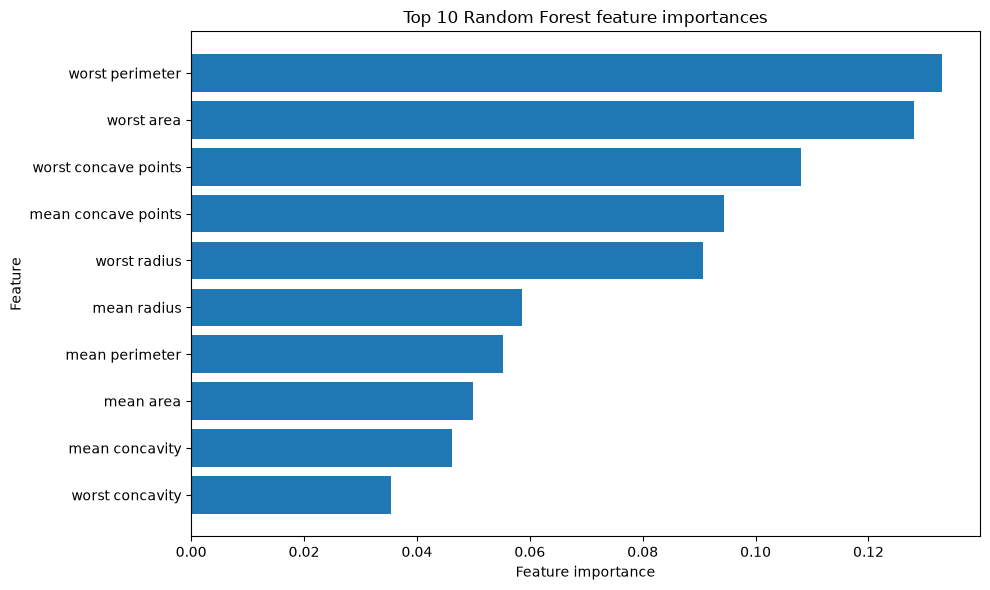

,Feature,Importance
0,worst perimeter,0.133100
1,worst area,0.128052
2,worst concave points,0.108107
3,mean concave points,0.094414
4,worst radius,0.090639
5,mean radius,0.058662
6,mean perimeter,0.055242
7,mean area,0.049938
8,mean concavity,0.046207
9,worst concavity,0.035357


In [13]:
importances = random_forest_model.feature_importances_
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importances
}).sort_values("Importance", ascending=False)

top_ten_importances = importance_df.head(10).sort_values(
    "Importance", ascending=True
)
plt.figure(figsize=(10, 6))
plt.barh(top_ten_importances["Feature"], top_ten_importances["Importance"])
plt.xlabel("Feature importance")
plt.ylabel("Feature")
plt.title("Top 10 Random Forest feature importances")
plt.tight_layout()
plt.show()

display(importance_df.head(10).reset_index(drop=True))


The ten most important features are dominated by measurements related to tumour size and shape. Worst perimeter (0.133), worst area (0.128), and worst concave points (0.108) are the three most important features.

Mean concave points, worst radius, and mean radius also contribute substantially. This suggests that the Random Forest relies strongly on tumour geometry and boundary characteristics when making predictions. Feature importance indicates predictive relevance within this model, not causation.

### Question 21

Random Forest is an ensemble of decision trees that combines bootstrap aggregation with random feature selection. At each split, each tree considers only a random subset of available features rather than evaluating every feature. This reduces correlation between trees and can improve the benefit obtained by averaging their predictions. Ordinary bagging of decision trees uses bootstrap samples but does not generally impose this same random feature subset at each split. Feature importance indicates how much the fitted model relies on a feature under the selected importance measure; it does not establish that the feature causes the target outcome.

## Task 6 — Boosting: AdaBoost and Gradient Boosting

### Question 22

In [14]:
# Construct AdaBoost compatibly across sklearn versions.
ada_signature = inspect.signature(AdaBoostClassifier)
ada_kwargs = {
    "n_estimators": 100,
    "learning_rate": 1.0,
    "random_state": RANDOM_STATE
}
if "estimator" in ada_signature.parameters:
    ada_kwargs["estimator"] = DecisionTreeClassifier(
        max_depth=1, random_state=RANDOM_STATE
    )
else:
    ada_kwargs["base_estimator"] = DecisionTreeClassifier(
        max_depth=1, random_state=RANDOM_STATE
    )

adaboost_model = AdaBoostClassifier(**ada_kwargs)
adaboost_result = evaluate_classifier(
    adaboost_model, X_train, y_train, X_test, y_test
)

gradient_boosting_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=RANDOM_STATE
)
gradient_boosting_result = evaluate_classifier(
    gradient_boosting_model, X_train, y_train, X_test, y_test
)

for model_name, model, result in [
    ("AdaBoost", adaboost_model, adaboost_result),
    ("Gradient Boosting", gradient_boosting_model, gradient_boosting_result)
]:
    print(model_name, "settings:", model.get_params())
    print({k: v for k, v in result.items() if k != "Confusion matrix"})
    print("Confusion matrix:")
    print(result["Confusion matrix"])


AdaBoost settings: {'estimator__ccp_alpha': 0.0, 'estimator__class_weight': None, 'estimator__criterion': 'gini', 'estimator__max_depth': 1, 'estimator__max_features': None, 'estimator__max_leaf_nodes': None, 'estimator__min_impurity_decrease': 0.0, 'estimator__min_samples_leaf': 1, 'estimator__min_samples_split': 2, 'estimator__min_weight_fraction_leaf': 0.0, 'estimator__monotonic_cst': None, 'estimator__random_state': 42, 'estimator__splitter': 'best', 'estimator': DecisionTreeClassifier(max_depth=1, random_state=42), 'learning_rate': 1.0, 'n_estimators': 100, 'random_state': 42}
{'Training accuracy': 1.0, 'Test accuracy': 0.956140350877193, 'Test precision': 0.9466666666666667, 'Test recall': 0.9861111111111112, 'Test F1-score': 0.9659863945578231}
Confusion matrix:
[[38  4]
 [ 1 71]]
Gradient Boosting settings: {'ccp_alpha': 0.0, 'criterion': 'deprecated', 'init': None, 'learning_rate': 0.1, 'loss': 'log_loss', 'max_depth': 3, 'max_features': None, 'max_leaf_nodes': None, 'min_impu

### Question 23

In [15]:
boosting_settings = pd.DataFrame([
    {
        "Model": "AdaBoost",
        "Number of estimators": adaboost_model.n_estimators,
        "Learning rate": adaboost_model.learning_rate,
        "Base learner": str(adaboost_model.estimator if hasattr(adaboost_model, "estimator")
                            else adaboost_model.base_estimator)
    },
    {
        "Model": "Gradient Boosting",
        "Number of estimators": gradient_boosting_model.n_estimators,
        "Learning rate": gradient_boosting_model.learning_rate,
        "Base learner/tree complexity": (
            f"Decision trees; max_depth={gradient_boosting_model.max_depth}, "
            f"max_leaf_nodes={gradient_boosting_model.max_leaf_nodes}"
        )
    }
])
display(boosting_settings)


,Model,Number of estimators,Learning rate,Base learner,Base learner/tree complexity
0,AdaBoost,100,1.0,"DecisionTreeClassifier(max_depth=1, random_sta...",NaN
1,Gradient Boosting,100,0.1,NaN,"Decision trees; max_depth=3, max_leaf_nodes=None"


### Question 24

In [16]:
boosting_evaluation = pd.DataFrame([
    {
        "Model": "AdaBoost",
        **{key: value for key, value in adaboost_result.items()
           if key != "Confusion matrix"}
    },
    {
        "Model": "Gradient Boosting",
        **{key: value for key, value in gradient_boosting_result.items()
           if key != "Confusion matrix"}
    }
])
display(boosting_evaluation)
print("AdaBoost confusion matrix:")
print(adaboost_result["Confusion matrix"])
print("Gradient Boosting confusion matrix:")
print(gradient_boosting_result["Confusion matrix"])


,Model,Training accuracy,Test accuracy,Test precision,Test recall,Test F1-score
0,AdaBoost,1.0,0.95614,0.946667,0.986111,0.965986
1,Gradient Boosting,1.0,0.95614,0.946667,0.986111,0.965986


AdaBoost confusion matrix:
[[38  4]
 [ 1 71]]
Gradient Boosting confusion matrix:
[[38  4]
 [ 1 71]]


### Question 25

,n_estimators,Validation accuracy,Validation F1
0,25,0.956044,0.964912
1,50,0.956044,0.964286
2,100,0.956044,0.964286
3,150,0.967033,0.973451
4,200,0.967033,0.973451


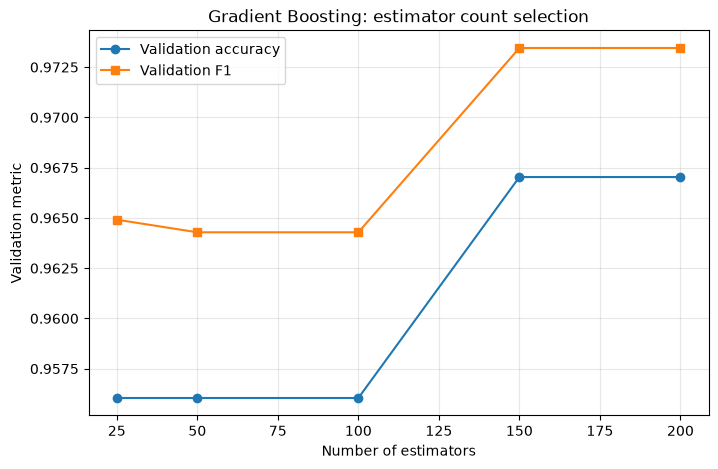

Selected n_estimators: 150


In [17]:
# Use a validation split drawn only from the original training partition.
X_fit, X_validation, y_fit, y_validation = train_test_split(
    X_train, y_train,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train
)

ESTIMATOR_COUNTS = [25, 50, 100, 150, 200]
boosting_validation_rows = []

for n_estimators in ESTIMATOR_COUNTS:
    candidate = GradientBoostingClassifier(
        n_estimators=n_estimators,
        learning_rate=0.1,
        max_depth=3,
        random_state=RANDOM_STATE
    )
    candidate.fit(X_fit, y_fit)
    validation_predictions = candidate.predict(X_validation)
    boosting_validation_rows.append({
        "n_estimators": n_estimators,
        "Validation accuracy": accuracy_score(
            y_validation, validation_predictions
        ),
        "Validation F1": f1_score(
            y_validation, validation_predictions,
            pos_label=POSITIVE_LABEL, zero_division=0
        )
    })

boosting_validation_df = pd.DataFrame(boosting_validation_rows)
display(boosting_validation_df)

plt.figure(figsize=(8, 5))
plt.plot(
    boosting_validation_df["n_estimators"],
    boosting_validation_df["Validation accuracy"],
    marker="o",
    label="Validation accuracy"
)
plt.plot(
    boosting_validation_df["n_estimators"],
    boosting_validation_df["Validation F1"],
    marker="s",
    label="Validation F1"
)
plt.xlabel("Number of estimators")
plt.ylabel("Validation metric")
plt.title("Gradient Boosting: estimator count selection")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Select using validation F1; refit selected configuration on all training data.
best_n_estimators = int(
    boosting_validation_df.loc[
        boosting_validation_df["Validation F1"].idxmax(),
        "n_estimators"
    ]
)
selected_gradient_boosting = GradientBoostingClassifier(
    n_estimators=best_n_estimators,
    learning_rate=0.1,
    max_depth=3,
    random_state=RANDOM_STATE
)
selected_gradient_boosting.fit(X_train, y_train)
print("Selected n_estimators:", best_n_estimators)


The validation experiment shows that increasing the number of estimators from 25 to 150 improves validation accuracy from 0.956 to 0.967 and validation F1-score from 0.965 to 0.973.

Increasing the number of estimators from 150 to 200 produces no further improvement. Therefore, 150 estimators is selected as the simpler configuration achieving the best observed validation F1-score. The experiment suggests that adding more learners initially improves generalization, but the improvement eventually plateaus.

### Question 26

Boosting builds learners sequentially, with each new learner depending on information from the current ensemble. AdaBoost increases the weights of observations that previous learners classified incorrectly, encouraging subsequent learners to focus on difficult examples. Gradient Boosting instead fits each new learner to reduce the remaining loss signal, commonly represented through negative gradients or residual-like quantities. Both methods combine a sequence of relatively weak learners into a stronger predictive model.

### Question 27

The learning rate controls the contribution of each new learner to the ensemble, while the number of estimators controls how many learners are added. A smaller learning rate generally requires more estimators to achieve a comparable level of fitting, whereas a larger learning rate can fit more quickly but may be more sensitive to overfitting. These parameters should therefore be considered together and selected using validation data or cross-validation. The observed validation experiment should be used to discuss the balance between model complexity and generalization, including the possibility that sequential learners focus too strongly on noisy observations.

**Interpretation of the estimator-count experiment, including the observed generalization trade-off and sensitivity to noisy examples:**

The experiment demonstrates that increasing the number of estimators initially improves validation performance. The best validation F1-score of 0.973 is achieved at both 150 and 200 estimators, with 150 selected.

The learning rate controls the contribution of each learner, while the number of estimators determines how many learners are added. A smaller learning rate generally requires more estimators, whereas a larger learning rate can increase the risk of overfitting. Excessive model complexity may also cause boosting algorithms to focus too strongly on noisy observations.


## Task 7 — Comparative Evaluation and Interpretation

### Question 28

In [18]:
comparison_models = [
    ("Decision Tree", baseline_tree, baseline_tree_result),
    ("Bagging", bagging_model, bagging_result),
    ("Random Forest", random_forest_model, random_forest_result),
    ("AdaBoost", adaboost_model, adaboost_result),
    ("Gradient Boosting", gradient_boosting_model, gradient_boosting_result)
]

comparison_rows = []
for model_name, model, result in comparison_models:
    comparison_rows.append({
        "Model": model_name,
        "Training accuracy": result["Training accuracy"],
        "Test accuracy": result["Test accuracy"],
        "Test precision": result["Test precision"],
        "Test recall": result["Test recall"],
        "Test F1-score": result["Test F1-score"]
    })

comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table.round(3))


,Model,Training accuracy,Test accuracy,Test precision,Test recall,Test F1-score
0,Decision Tree,1.0,0.912,0.956,0.903,0.929
1,Bagging,1.0,0.939,0.945,0.958,0.952
2,Random Forest,1.0,0.956,0.959,0.972,0.966
3,AdaBoost,1.0,0.956,0.947,0.986,0.966
4,Gradient Boosting,1.0,0.956,0.947,0.986,0.966


### Question 29

All models use the same 80:20 stratified train-test split, the same held-out test observations, and the same metric definitions. Precision, recall, and F1-score use class 1 as the positive class and set `zero_division=0`. The confusion matrices use label order [0, 1], with rows representing true labels and columns representing predicted labels. Reported comparison metrics are rounded consistently to three decimal places.

### Question 30

**Strongest model for the selected objective:**

Random Forest, AdaBoost, and Gradient Boosting achieve the highest test accuracy of 0.956 and approximately equal F1-scores of 0.966.

For the selected objective of achieving a strong balance between precision and recall for the positive class (benign), AdaBoost and Gradient Boosting achieve the highest recall of 0.986. Random Forest achieves slightly higher precision of 0.959.

Therefore, AdaBoost or Gradient Boosting can be preferred when positive-class recall is prioritized, while Random Forest offers a slightly better precision-recall balance. In medical diagnosis, malignant-class recall must also be considered separately because malignant is class 0 in this dataset.


### Question 31

The single decision tree is the most interpretable model, as its predictions can be represented through explicit decision rules. However, it achieves lower test accuracy and F1-score than the ensemble methods.

Bagging improves generalization by combining multiple trees, while Random Forest additionally introduces random feature selection. AdaBoost and Gradient Boosting achieve strong predictive performance through sequential learning.

Ensemble methods generally require more computation and are less straightforward to interpret than a single tree. Random Forest provides a strong balance between predictive performance and computational practicality, while a single decision tree remains preferable when transparency and interpretability are the primary requirements.


## Task 8 — Conceptual Analysis

### Question 32

A deep decision tree can continue splitting the training data until it captures very specific patterns, including random fluctuations and noise. This can produce very high training accuracy because the tree has enough complexity to fit many individual observations. However, these detailed rules may not represent general patterns in the underlying population. As a result, predictions on unseen observations can be less accurate, which is overfitting.

### Question 33

Decision trees are unstable learners because small changes in the training sample can lead to different split choices and substantially different tree structures. Bagging trains multiple trees on bootstrap samples and combines their predictions, reducing the effect of variation in any one fitted tree. The improvement may be limited when the base learners are highly correlated, when the underlying data has strong bias, or when the dataset is too small or noisy for bootstrap samples to provide useful diversity.

### Question 34

Boosting does not always outperform bagging. Bagging primarily reduces variance by combining independently trained models, while boosting builds learners sequentially to improve errors made by the current ensemble and can reduce bias. The outcome depends on model capacity, data characteristics, and the balance between bias and variance. Boosting can be sensitive to noisy or incorrectly labelled observations because later learners may focus heavily on examples that are difficult to classify.

### Question 35

Learning rate determines how strongly each new learner contributes to the boosted ensemble, while the number of estimators determines how many sequential learners are added. A lower learning rate usually requires a larger number of estimators to achieve comparable fitting. A higher learning rate may reach a good training fit with fewer learners but can reduce generalization if the ensemble becomes too aggressive. They should be tuned together using validation data or cross-validation rather than selected independently.

### Question 36

Repeatedly tuning a model on the test set makes the test set part of the model-selection process. Decisions become indirectly adapted to the test observations, so the final test metrics no longer provide an unbiased estimate of performance on unseen data. Training data is used to fit model parameters, while validation data or cross-validation is used to select hyperparameters and compare candidate configurations. The test set should be held aside until the final evaluation, after model selection is complete.

### Question 37

In medical diagnosis, interpretability may be more important than a small increase in predictive performance. A clinician may need to understand which patient measurements contributed to a prediction before using it to support a decision. A decision tree can express its predictions through explicit feature-based rules that are easier to inspect and communicate than many complex ensemble predictions. The final choice should still consider predictive performance, clinical validation, and the consequences of false positive and false negative decisions.

## Conclusion

This assignment explored Decision Trees, Bagging, Random Forest, AdaBoost, and Gradient Boosting using the Breast Cancer Wisconsin Diagnostic dataset. All models were trained and evaluated using the same stratified 80:20 training-test split to ensure a fair comparison.

The baseline Decision Tree achieved 1.000 training accuracy and 0.912 test accuracy, indicating a gap between training and generalization performance. Experiments with different tree depths showed that a maximum depth of 3 provided the best test accuracy of 0.939 and F1-score of 0.952 among the tested configurations. Increasing tree depth beyond this point increased training accuracy but reduced test performance, suggesting overfitting.

Comparing impurity criteria showed that Gini and entropy produced nearly identical test accuracy, although their learned tree structures and predictions differed slightly. The numerical split calculation demonstrated how weighted child impurity determines the impurity reduction used for selecting tree splits.

Bagging improved test accuracy to 0.939 and F1-score to 0.952, supporting its ability to reduce variance through bootstrap aggregation. Random Forest achieved 0.956 test accuracy and 0.966 F1-score, benefiting from additional random feature selection. AdaBoost and Gradient Boosting also achieved 0.956 test accuracy and approximately 0.966 F1-score. Their recall for the positive class reached 0.986.

The boosting experiment showed that increasing the number of estimators improved validation performance up to 150 estimators, after which performance remained unchanged at 200.

Overall, ensemble methods provided better predictive performance than the baseline decision tree. Random Forest offers a strong balance of precision, recall, and generalization, while AdaBoost and Gradient Boosting provide higher positive-class recall. However, the positive class represents benign observations, so malignant-class recall must also be considered in an actual diagnostic application.

A single decision tree remains valuable when interpretability is essential. The main limitation of this experiment is that evaluation was performed on one train-test split, and further validation would be necessary before applying these models in clinical settings.